# Week 1 — Data exploration: historical freight load pricing

**Question.** What rate per mile should the platform quote for a load on a given lane — can we predict
`agreed_rate_per_mile` *before the load is posted*?

**What this notebook does.** It describes the dataset and its problems before any model is fitted.

**Ground rules followed here**

- The holdout file is sealed until week 4 and is never read. `src.data.load_holdout()` raises unless it is deliberately unsealed.
- Sections 1–3 describe the columns themselves (schema, missing values, ranges, consistency) on the whole training file.
- From section 4 on, anything that relates a feature to the target uses the **train split only**, so the validation
  split stays an honest check on decisions that come out of this exploration.
- No model is fitted. The associations in section 6 are permutation tests on group means and rank correlations.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import checks
from src.data import (
    CATEGORICAL_FEATURES, ID_COL, NUMERIC_FEATURES, POST_OUTCOME_COLUMNS, QUOTE_TIME_FEATURES, SEED,
    TARGET, TARGET_DOCUMENTED_RANGE, TIMING_SUSPECT_COLUMNS, URGENT_HOURS,
    load_train, pickup_regime, split_train_validation,
)
from src.plotstyle import BLUE, CONTEXT_GRAY, INK_SECONDARY, MUTED, ORANGE, apply_style

apply_style()
pd.set_option("display.max_columns", 20)

## 1. Load the training file

`load_train()` drops the post-outcome column by default. It is requested explicitly here, and only here,
so the leak can be documented in section 6.

In [2]:
raw = load_train(include_post_outcome=True)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

2,400 rows x 12 columns


,load_id,origin_market,destination_market,equipment_type,load_weight_lbs,lane_distance_miles,hours_to_pickup,day_of_week_posted,carrier_bids_received,shipper_tier,finance_settlement_code,agreed_rate_per_mile
0,TR-00001,NaN,Southeast,Flatbed,31748.0,907.0,109.85,Monday,18.0,Enterprise,at_or_below_forecast,1.68
1,TR-00002,Mountain West,Southeast,Step Deck,9417.0,692.0,124.29,NaN,19.0,Trial,at_or_below_forecast,1.19
2,TR-00003,Southeast,Southeast,Flatbed,26171.0,1529.0,149.01,Monday,32.0,Enterprise,above_forecast,8.53
3,TR-00004,Texas Gulf,Southeast,Flatbed,28170.0,2385.0,95.70,Monday,24.0,Enterprise,above_forecast,6.91
4,TR-00005,Southeast,Southeast,Step Deck,32665.0,2812.0,37.60,Monday,20.0,Enterprise,at_or_below_forecast,3.79


In [3]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_missing": raw.isna().sum()})

,dtype,n_unique,n_missing
load_id,str,2400,0
origin_market,str,6,170
destination_market,str,6,166
equipment_type,str,5,0
load_weight_lbs,float64,2169,165
lane_distance_miles,float64,1527,157
hours_to_pickup,float64,2080,193
day_of_week_posted,str,7,155
carrier_bids_received,float64,35,146
shipper_tier,str,4,192


## 2. When is each column known?

The data dictionary's *Available* column decides what may be a model input. Two columns need a decision.

In [4]:
availability = pd.DataFrame(
    [(c, "feature", "at collection", "use") for c in QUOTE_TIME_FEATURES]
    + [(c, "feature", "dictionary: at collection / definition: after posting", "exclude until confirmed")
       for c in TIMING_SUSPECT_COLUMNS]
    + [(c, "post-outcome", "after the outcome is known", "never a model input") for c in POST_OUTCOME_COLUMNS]
    + [(TARGET, "target", "after the outcome is known", "predict"),
       (ID_COL, "identifier", "at collection", "never a model input")],
    columns=["column", "role", "available", "decision"],
).set_index("column")
availability

,role,available,decision
column,,,
load_weight_lbs,feature,at collection,use
lane_distance_miles,feature,at collection,use
hours_to_pickup,feature,at collection,use
origin_market,feature,at collection,use
destination_market,feature,at collection,use
equipment_type,feature,at collection,use
day_of_week_posted,feature,at collection,use
shipper_tier,feature,at collection,use
carrier_bids_received,feature,dictionary: at collection / definition: after ...,exclude until confirmed


In [5]:
raw["finance_settlement_code"].value_counts(dropna=False).to_frame("rows")

,rows
finance_settlement_code,
at_or_below_forecast,1439
above_forecast,696
NaN,265


**`finance_settlement_code` is leakage.** Finance writes it after the carrier invoice is reconciled, long after the
rate is agreed. The dictionary describes it as a "short alphanumeric code", but the column actually holds two labels,
`above_forecast` and `at_or_below_forecast` — a statement about the outcome itself. Section 6 measures how strongly it
gives the target away. It is excluded from every feature set (`src.data.load_train()` drops it by default).

**`carrier_bids_received` is a timing question.** The dictionary marks it "At collection", but defines it as the number
of bids received *before the shipper accepted a rate* — bids only arrive after a load is posted, and the task is to quote
before posting. It is kept out of the default feature set (`QUOTE_TIME_FEATURES`) until the mentor confirms when it is
known. Section 6 shows that leaving it out costs nothing.

## 3. Data-quality problems

These checks look at the columns themselves, not at how features relate to the target.

In [6]:
checks.audit(raw)

,value
check,
rows,2400
duplicate load_id,0
duplicate rows ignoring load_id,0
rows with >= 1 missing feature,1065
pct rows with >= 1 missing feature,44.4
target below documented min 1.05,7
target above documented max 9.8,17
urgent loads (hours_to_pickup < 2),15
loads with hours_to_pickup missing,193


### 3.1 Missing values

rows by number of missing features: {0: 1335, 1: 821, 2: 213, 3: 27, 4: 4}
largest |correlation| between two missingness indicators: 0.05
columns with no missing values: ['load_id', 'equipment_type', 'agreed_rate_per_mile']


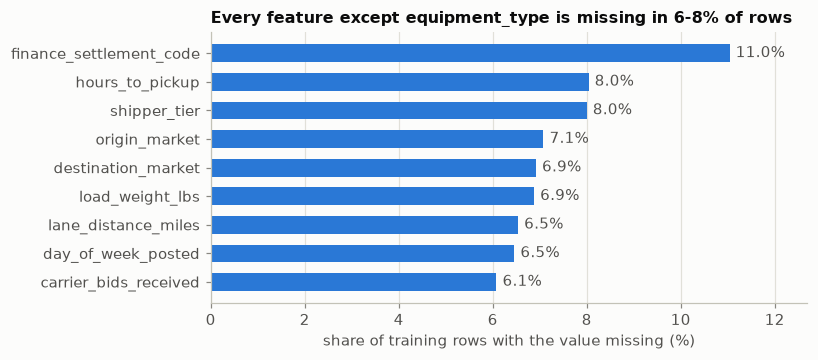

In [7]:
miss = checks.missingness(raw)
miss = miss[miss["n_missing"] > 0]

features = raw[checks.FEATURES]
rows_by_n_missing = features.isna().sum(axis=1).value_counts().sort_index()
indicators = features.loc[:, features.isna().any()].isna().astype(int)
indicator_corr = indicators.corr().where(~np.eye(indicators.shape[1], dtype=bool))
print("rows by number of missing features:", rows_by_n_missing.to_dict())
print(f"largest |correlation| between two missingness indicators: {indicator_corr.abs().max().max():.2f}")
print("columns with no missing values:", [c for c in raw.columns if raw[c].notna().all()])

fig, ax = plt.subplots(figsize=(7, 3.2))
ordered = miss.sort_values("pct_missing")
bars = ax.barh(ordered.index, ordered["pct_missing"], color=BLUE, height=0.62)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in ordered["pct_missing"]], padding=4, color=INK_SECONDARY)
ax.set_xlim(0, ordered["pct_missing"].max() * 1.15)
ax.set_xlabel("share of training rows with the value missing (%)")
ax.set_title("Every feature except equipment_type is missing in 6-8% of rows")
ax.grid(axis="y", visible=False)
plt.show()

- Every feature except `equipment_type` is missing in 6.1–8.0% of rows (the post-outcome column in 11.0%).
- Because the gaps fall on different rows, **1,065 of 2,400 loads (44.4%) have at least one missing feature**
  (821 have one, 213 two, 27 three, 4 four). Dropping incomplete rows would throw away almost half the data.
- No structure found: the largest correlation between any two missingness indicators is 0.05, and in section 6 the
  "(missing)" level of each categorical column prices like the rest.
- The dictionary states that empty cells are genuinely missing, not zero, so they must never be filled with 0.

**What this changes:** impute and add a missing-indicator per column, with the imputation values learned inside each
training fold only (imputing from the full file would leak validation rows into training).

### 3.2 Target values outside the documented range

In [8]:
lo, hi = TARGET_DOCUMENTED_RANGE
out_of_range = checks.target_outside_documented_range(raw)
below, above = out_of_range[out_of_range[TARGET] < lo], out_of_range[out_of_range[TARGET] > hi]
print(f"documented range: {lo} - {hi} USD/mile")
print(f"observed range:   {raw[TARGET].min()} - {raw[TARGET].max()} USD/mile")
print(f"below {lo}: {len(below)} rows (lowest {below[TARGET].min()})")
print(f"above {hi}: {len(above)} rows (highest {above[TARGET].max()})")
print(f"total: {len(out_of_range)} rows = {100 * len(out_of_range) / len(raw):.1f}% of the training file")

documented range: 1.05 - 9.8 USD/mile
observed range:   1.0 - 10.14 USD/mile
below 1.05: 7 rows (lowest 1.0)
above 9.8: 17 rows (highest 10.14)
total: 24 rows = 1.0% of the training file


The dictionary gives the target range as 1.05–9.8. The training file runs from 1.00 to 10.14: 24 loads (1.0%) fall
outside, 7 just below and 17 above. They sit close to the bounds rather than far out, which looks more like a stale
range in the dictionary than like data-entry errors, but I cannot tell which from the data alone.

**What this changes:** the rows are kept and not clipped. The documented range should not be hard-coded as an output
clip or sanity check without asking the mentor first.

### 3.3 Categorical columns are dominated by one level

In [9]:
checks.category_balance(raw)

,n_levels,top_level,top_share_pct,smallest_level,smallest_level_rows
column,,,,,
origin_market,6,Southeast,78.1,Texas Gulf,90
destination_market,6,Southeast,77.6,Mountain West,91
equipment_type,5,Reefer,24.9,Intermodal,115
day_of_week_posted,7,Monday,77.9,Thursday,70
shipper_tier,4,Enterprise,77.5,SMB,157


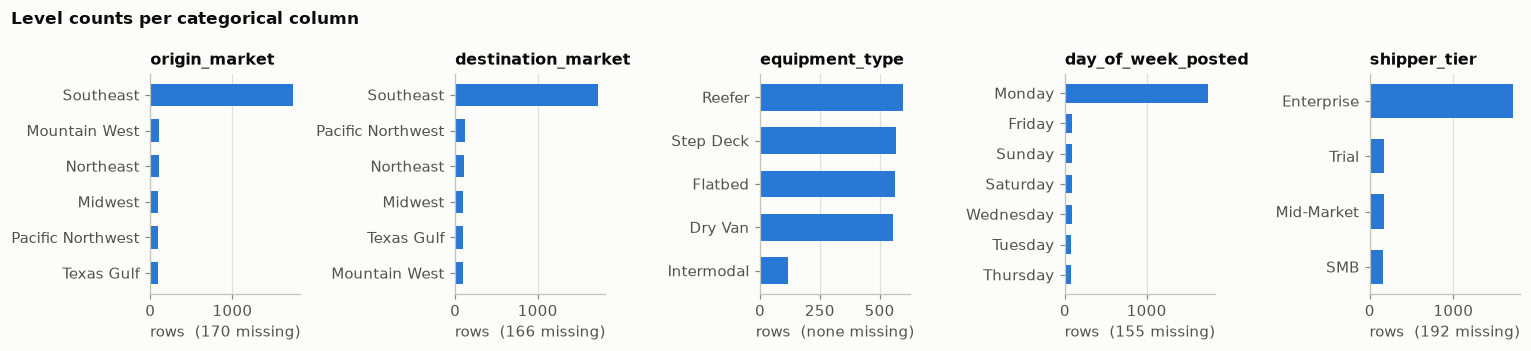

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    counts = raw[col].value_counts().sort_values()
    ax.barh(counts.index, counts.to_numpy(), color=BLUE, height=0.62)
    n_missing = int(raw[col].isna().sum())
    ax.set_title(col)
    ax.set_xlabel(f"rows  ({n_missing} missing)" if n_missing else "rows  (none missing)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Level counts per categorical column", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [11]:
known_lane = raw.dropna(subset=["origin_market", "destination_market"])
pair_counts = known_lane.groupby(["origin_market", "destination_market"]).size().unstack(fill_value=0)
flat = pair_counts.stack()
print(f"market pairs with zero rows: {[f'{o} -> {d}' for (o, d), n in flat.items() if n == 0]}")
print(f"market pairs with fewer than 10 rows: {(flat < 10).sum()} of {flat.size}")
print(f"rows on the Southeast -> Southeast lane: {flat[('Southeast', 'Southeast')]} "
      f"({100 * flat[('Southeast', 'Southeast')] / flat.sum():.0f}% of rows with both markets known)")
pair_counts

market pairs with zero rows: ['Texas Gulf -> Mountain West']
market pairs with fewer than 10 rows: 25 of 36
rows on the Southeast -> Southeast lane: 1256 (60% of rows with both markets known)


destination_market,Midwest,Mountain West,Northeast,Pacific Northwest,Southeast,Texas Gulf
origin_market,,,,,,
Midwest,4,7,5,4,64,2
Mountain West,2,3,7,6,76,5
Northeast,3,3,4,3,83,2
Pacific Northwest,4,2,4,7,70,1
Southeast,72,67,72,85,1256,72
Texas Gulf,4,0,4,5,64,5


- **One level holds about 78% of each column:** Southeast for both origin and destination, Monday for posting day,
  Enterprise for shipper tier (shares of non-missing values). `equipment_type` is the exception: four types near 25%
  each plus Intermodal with 115 loads.
- Every other level has between 70 and 171 loads.
- **Lanes are far sparser than the columns suggest.** 60% of loads with both markets known are Southeast → Southeast;
  25 of the 36 origin–destination pairs have fewer than 10 loads, and Texas Gulf → Mountain West never occurs.
- Three unrelated columns sharing an almost identical 78% share, and 78% of loads being posted on a Monday, is not what
  I would expect from real posting behaviour. It may be a default value written upstream. The data cannot confirm this,
  so it is a question for the mentor rather than a finding.

**What this changes:** lane-level (origin × destination) effects cannot be estimated outside lanes touching Southeast, so
origin and destination have to be treated as separate effects. The model will meet market pairs it has never seen, which
is exactly the "inputs it has never seen" case the ML engineer asked about.

### 3.4 Lane distance does not agree with the market labels

,count,mean,std,min,25%,50%,75%,max
cross market,740.0,1498.0,800.0,56.0,839.0,1524.0,2224.0,2847.0
same market,1200.0,1455.0,801.0,49.0,798.0,1420.0,2163.0,2849.0


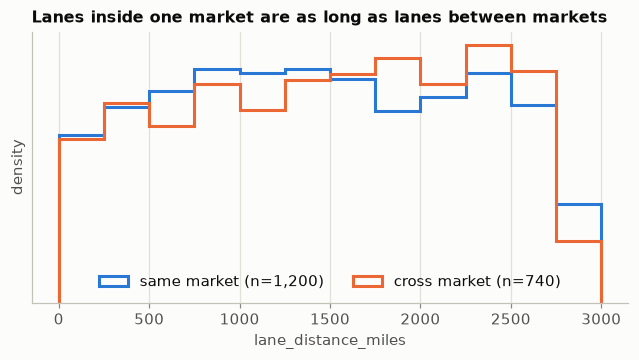

In [12]:
lane_type = np.where(known_lane["origin_market"] == known_lane["destination_market"], "same market", "cross market")
display(checks.lane_distance_by_lane_type(raw))

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, 3001, 250)
for label, color in [("same market", BLUE), ("cross market", ORANGE)]:
    values = known_lane.loc[lane_type == label, "lane_distance_miles"].dropna()
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=2, color=color,
            label=f"{label} (n={len(values):,})")
ax.set_xlabel("lane_distance_miles")
ax.set_ylabel("density")
ax.set_yticks([])
ax.set_title("Lanes inside one market are as long as lanes between markets")
ax.legend(loc="lower center", ncols=2)
plt.show()

Loads whose origin and destination are in the *same* broad market have a median distance of 1,420 miles and reach
2,849 miles; loads between *different* markets have a median of 1,524 and reach 2,847. The two distributions are
practically the same.

A lane that starts and ends inside one region should not be 2,800 miles long, so for many rows the market labels and the
distance cannot both be right. That matches the two warnings in the project notes: lane metadata comes from a geocoding
job that sometimes resolves to stale zones, and distance comes from two routing engines that disagree with each other.

**What this changes:**
- No feature should assume the two agree (for example "cross-market means long haul").
- Never join or de-duplicate on exact distance. This export has no city-level key, so the 15–20 mile disagreement
  between routing engines cannot be measured here; what can be checked is that there are no duplicate `load_id`s and no
  duplicate rows.

### 3.5 Numeric features

,count,mean,std,min,25%,50%,75%,max
load_weight_lbs,2235.0,22923.1,12033.7,2070.0,12285.5,23079.0,33303.5,43987.0
lane_distance_miles,2243.0,1470.0,803.1,49.0,800.5,1474.0,2188.0,2849.0
hours_to_pickup,2207.0,83.5,49.0,0.6,40.2,84.1,126.2,167.8
carrier_bids_received,2254.0,17.3,9.9,0.0,9.0,18.0,26.0,34.0


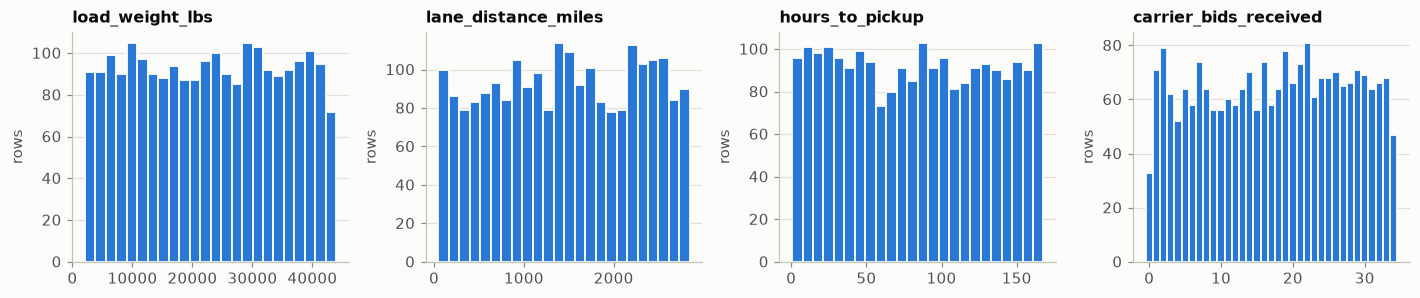

loads with zero carrier bids but an agreed rate: 33


In [13]:
display(raw[NUMERIC_FEATURES].describe().T.round(1))

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, col in zip(axes, NUMERIC_FEATURES):
    values = raw[col].dropna()
    # bid counts are integers: one bar per value, otherwise the bars alias into a comb
    bins = np.arange(-0.5, values.max() + 1) if col == "carrier_bids_received" else 24
    ax.hist(values, bins=bins, color=BLUE, edgecolor=plt.rcParams["axes.facecolor"], linewidth=1.2)
    ax.set_title(col)
    ax.set_ylabel("rows")
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print("loads with zero carrier bids but an agreed rate:", int((raw["carrier_bids_received"] == 0).sum()))

- All four numeric features are spread almost evenly across their range, with no negative values and no impossible
  zeros in weight or distance. `hours_to_pickup` stops just short of 168 hours, one week.
- **33 loads show zero carrier bids and still have an agreed rate.** By the column's own definition a rate was accepted
  with no carrier response. Together with the timing question in section 2 this is a second reason not to rely on
  `carrier_bids_received`.

## 4. Train / validation split

Fixed here, once, so every later decision is checked against the same rows.

In [14]:
train, valid = split_train_validation(load_train())  # leak column is not loaded
assert not set(train[ID_COL]) & set(valid[ID_COL])

def describe_split(df):
    regime = pickup_regime(df).value_counts()
    return {
        "rows": f"{len(df):,}",
        "target mean (USD/mile)": f"{df[TARGET].mean():.2f}",
        "target median (USD/mile)": f"{df[TARGET].median():.2f}",
        f"urgent loads (< {URGENT_HOURS:g}h)": f"{regime.get('urgent', 0):,}",
        "standard loads": f"{regime.get('standard', 0):,}",
        "hours_to_pickup missing": f"{regime.get('unknown', 0):,}",
    }

pd.DataFrame({"train": describe_split(train), "validation": describe_split(valid)})

,train,validation
rows,"1,921",479
target mean (USD/mile),4.27,4.27
target median (USD/mile),3.67,3.76
urgent loads (< 2h),12,3
standard loads,"1,754",438
hours_to_pickup missing,155,38


- 80/20 with a fixed seed: 1,921 train / 479 validation loads, stratified on pickup regime × target quintile so both
  sides have the same rate distribution.
- **Why a random split:** the export has no timestamp, no shipper key and no lane key, and no duplicate loads, so there
  is nothing to order by or group on. Section 5 checks the only ordering available (`load_id`) for drift.
- **Known weak point:** only 12 urgent loads land in train and 3 in validation. A single split cannot say anything
  reliable about the regime that matters most; section 7 comes back to this.

## 5. The target (train split)

,count,mean,std,min,25%,50%,75%,max
agreed_rate_per_mile,1921.0,4.27,2.49,1.0,2.14,3.67,6.19,10.14


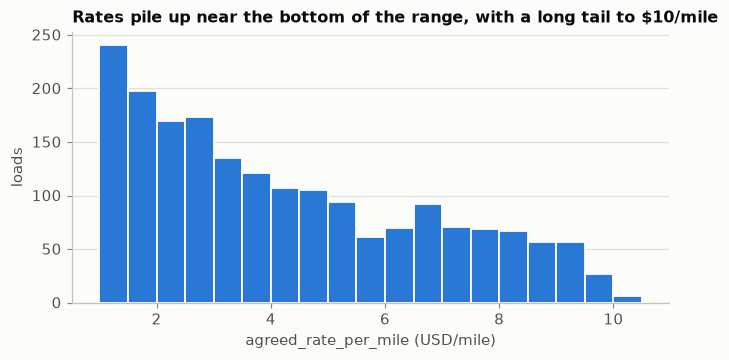

In [15]:
display(train[TARGET].describe().round(2).to_frame().T)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(train[TARGET], bins=np.arange(1.0, 10.51, 0.5), color=BLUE,
        edgecolor=plt.rcParams["axes.facecolor"], linewidth=1.2)
ax.set_xlabel("agreed_rate_per_mile (USD/mile)")
ax.set_ylabel("loads")
ax.set_title("Rates pile up near the bottom of the range, with a long tail to $10/mile")
ax.grid(axis="x", visible=False)
plt.show()

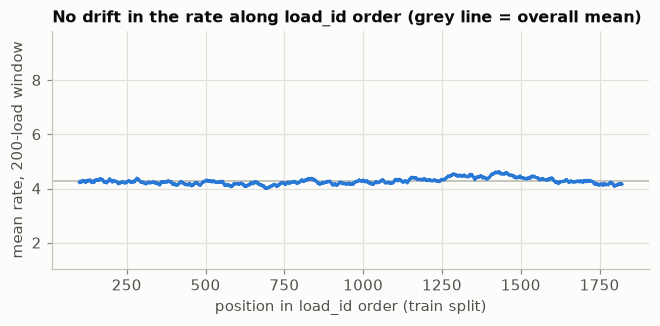

rolling mean stays between 4.00 and 4.64; overall mean 4.27


In [16]:
by_id = train.sort_values(ID_COL)[TARGET].reset_index(drop=True)
rolling = by_id.rolling(200, center=True).mean()

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.axhline(by_id.mean(), color=CONTEXT_GRAY, linewidth=1.2)
ax.plot(rolling.index, rolling, color=BLUE)
ax.set_ylim(*TARGET_DOCUMENTED_RANGE)
ax.set_xlabel("position in load_id order (train split)")
ax.set_ylabel("mean rate, 200-load window")
ax.set_title("No drift in the rate along load_id order (grey line = overall mean)")
plt.show()
print(f"rolling mean stays between {rolling.min():.2f} and {rolling.max():.2f}; overall mean {by_id.mean():.2f}")

- Train split: mean 4.27, median 3.67, standard deviation 2.49 USD/mile, middle half of loads between 2.14 and 6.19.
- The distribution is right-skewed: the most common rates sit just above $1/mile and the frequency falls steadily up
  to $10/mile. Errors on the tail will dominate a squared-error metric, which is one reason the reference metric in
  section 8 is absolute error.
- The rolling mean along `load_id` order stays between 4.00 and 4.64 around an overall 4.27: no visible drift. Without a
  timestamp this is the only ordering check possible, and it does not rule out seasonality.

## 6. Which columns tell us anything about the rate? (train split)

No model — for each column, how much of the target it accounts for and whether that is distinguishable from a shuffled
target. Categorical columns use eta squared (share of target variance explained by level means, missing as its own
level); numeric columns use the Spearman rank correlation.

In [17]:
raw_train = raw[raw[ID_COL].isin(train[ID_COL])]  # same rows as `train`, with the leak column, for this section only
assoc = checks.association_with_target(raw_train, checks.FEATURES + POST_OUTCOME_COLUMNS)
assoc

,measure,value,perm_p_value
column,,,
load_weight_lbs,spearman_rho,-0.0235,0.3143
lane_distance_miles,spearman_rho,0.0343,0.1544
hours_to_pickup,spearman_rho,-0.0576,0.0170
carrier_bids_received,spearman_rho,0.0095,0.6942
origin_market,eta_squared,0.0022,0.6367
destination_market,eta_squared,0.0005,0.9845
equipment_type,eta_squared,0.0007,0.8711
day_of_week_posted,eta_squared,0.0026,0.6647
shipper_tier,eta_squared,0.0002,0.9860


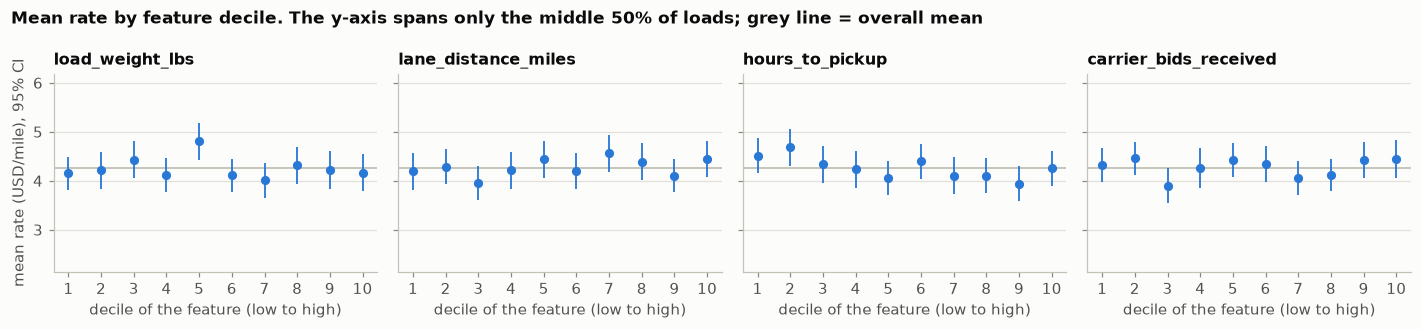

In [18]:
overall_mean = train[TARGET].mean()
q25, q75 = train[TARGET].quantile([0.25, 0.75])

fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, col in zip(axes, NUMERIC_FEATURES):
    binned = train.groupby(pd.qcut(train[col], 10, duplicates="drop"), observed=True)[TARGET].agg(["mean", "sem"])
    ax.axhline(overall_mean, color=CONTEXT_GRAY, linewidth=1.2)
    ax.errorbar(np.arange(1, len(binned) + 1), binned["mean"], yerr=1.96 * binned["sem"],
                fmt="o", color=BLUE, markersize=5, elinewidth=1.2)
    ax.set_title(col)
    ax.set_xlabel("decile of the feature (low to high)")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(q25, q75)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mean rate (USD/mile), 95% CI")
fig.suptitle("Mean rate by feature decile. The y-axis spans only the middle 50% of loads; grey line = overall mean",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

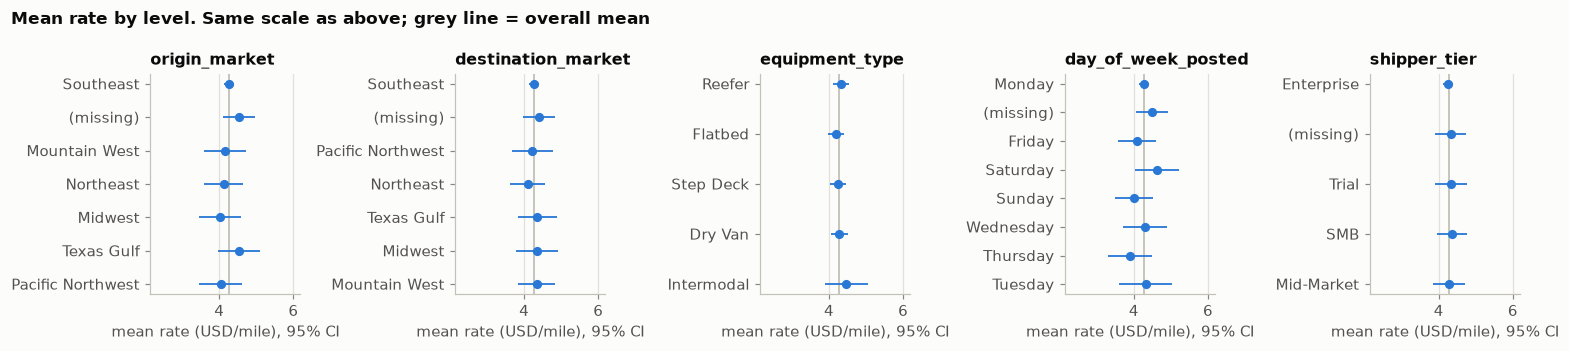

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2), sharex=True)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    by_level = train.groupby(train[col].fillna("(missing)"))[TARGET].agg(["mean", "sem", "count"]).sort_values("count")
    ax.axvline(overall_mean, color=CONTEXT_GRAY, linewidth=1.2)
    ax.errorbar(by_level["mean"], by_level.index, xerr=1.96 * by_level["sem"],
                fmt="o", color=BLUE, markersize=5, elinewidth=1.2)
    ax.set_title(col)
    ax.set_xlim(q25, q75)
    ax.set_xlabel("mean rate (USD/mile), 95% CI")
    ax.grid(axis="y", visible=False)
fig.suptitle("Mean rate by level. Same scale as above; grey line = overall mean",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

,count,mean,median
finance_settlement_code,,,
(missing),204,4.13,3.54
above_forecast,559,7.17,7.29
at_or_below_forecast,1158,2.89,2.71


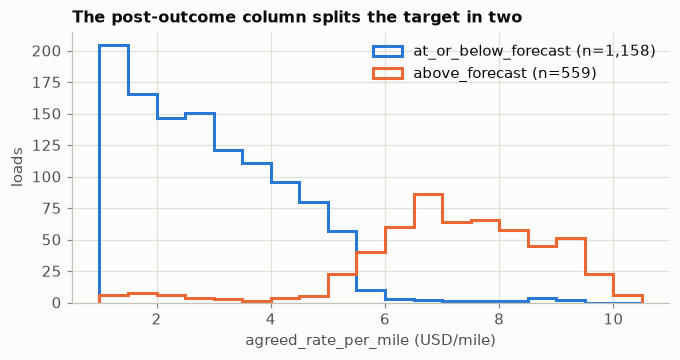

In [20]:
leak = raw_train["finance_settlement_code"]
display(raw_train.groupby(leak.fillna("(missing)"))[TARGET].agg(["count", "mean", "median"]).round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(1.0, 10.51, 0.5)
for label, color in [("at_or_below_forecast", BLUE), ("above_forecast", ORANGE)]:
    ax.hist(raw_train.loc[leak == label, TARGET], bins=bins, histtype="step", linewidth=2, color=color,
            label=f"{label} (n={(leak == label).sum():,})")
ax.set_xlabel("agreed_rate_per_mile (USD/mile)")
ax.set_ylabel("loads")
ax.set_title("The post-outcome column splits the target in two")
ax.legend()
plt.show()

**The only column that explains the rate is the one that does not exist at quote time.**

- `finance_settlement_code` accounts for **58% of the variance of the target on its own** (eta squared 0.58).
  `above_forecast` loads average 7.17 USD/mile against 2.89 for `at_or_below_forecast`, and the two groups separate at
  roughly $5.5/mile. A model given this column would score very well and be useless before a load is posted.
- **None of the nine legitimate columns comes close.** Each categorical column explains under 0.3% of the variance
  (permutation p between 0.64 and 0.99). The numeric rank correlations are all below 0.06 in absolute value.
- `hours_to_pickup` is the only one distinguishable from a shuffled target (rho = −0.058, p ≈ 0.02): shorter notice goes
  with a slightly higher rate, which is the plausible direction. With nine columns tested, a p of 0.02 would not survive
  a multiple-comparison correction (0.05 / 9 ≈ 0.006), so this is a hint and not a result.
- `carrier_bids_received` shows nothing (rho = 0.01, p = 0.69), so excluding it over the timing question costs nothing.

**Limits of this section.** These are one-column-at-a-time tests. They cannot rule out signal that only appears in
combinations of features; that is for week 2 models to test against the reference number in section 8.

**What this changes:** expectations. A model restricted to quote-time features may improve on a constant quote only
modestly. If a later model suddenly scores well, the first thing to check is leakage.

## 7. The urgent-pickup regime (train split)

The ML engineer's note says loads posted less than about two hours before pickup behave like a separate distribution,
and that this is where the model has to perform.

,n,mean,median,sem
hours_to_pickup,,,,
< 2h,12,4.61,4.38,0.59
2-6h,46,4.83,4.32,0.36
6-12h,71,4.40,4.26,0.29
12-24h,125,4.38,3.68,0.23
24-48h,278,4.55,4.03,0.15
48-96h,482,4.18,3.69,0.11
96-168h,752,4.15,3.39,0.09
missing,155,4.27,3.89,0.21


urgent loads: n=12, mean 4.61, bootstrap 95% CI 3.58 - 5.77
standard loads: n=1,754, mean 4.27


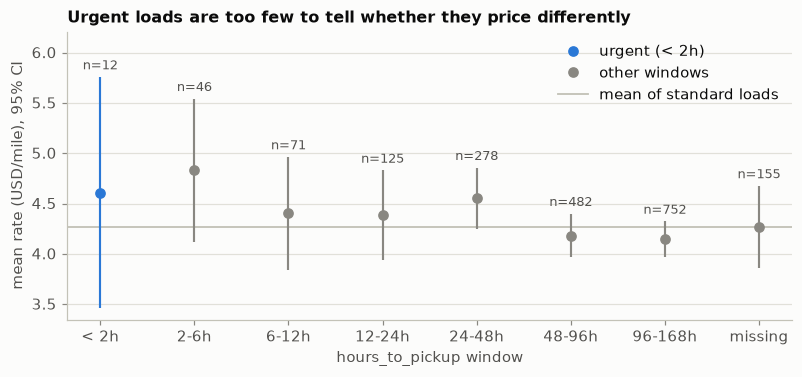

In [21]:
edges = [0, 2, 6, 12, 24, 48, 96, 168]
labels = ["< 2h", "2-6h", "6-12h", "12-24h", "24-48h", "48-96h", "96-168h"]
window = pd.cut(train["hours_to_pickup"], edges, right=False, labels=labels)
window = window.cat.add_categories("missing").fillna("missing")
by_window = train.groupby(window, observed=False)[TARGET].agg(n="count", mean="mean", median="median", sem="sem")
display(by_window.round(2))

rng = np.random.default_rng(SEED)
urgent = train.loc[pickup_regime(train) == "urgent", TARGET].to_numpy()
standard = train.loc[pickup_regime(train) == "standard", TARGET].to_numpy()
boot = rng.choice(urgent, size=(10_000, len(urgent))).mean(axis=1)
ci_lo, ci_hi = np.quantile(boot, [0.025, 0.975])
print(f"urgent loads: n={len(urgent)}, mean {urgent.mean():.2f}, bootstrap 95% CI {ci_lo:.2f} - {ci_hi:.2f}")
print(f"standard loads: n={len(standard):,}, mean {standard.mean():.2f}")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
colors = [BLUE] + [MUTED] * (len(by_window) - 1)
ax.axhline(standard.mean(), color=CONTEXT_GRAY, linewidth=1.2)
for x, (label, row), color in zip(range(len(by_window)), by_window.iterrows(), colors):
    ax.errorbar(x, row["mean"], yerr=1.96 * row["sem"], fmt="o", color=color, markersize=6, elinewidth=1.4)
    ax.annotate(f"n={int(row['n'])}", (x, row["mean"] + 1.96 * row["sem"]), textcoords="offset points",
                xytext=(0, 5), ha="center", color=INK_SECONDARY, fontsize=8.5)
ax.set_xticks(range(len(by_window)), by_window.index)
ax.set_ylim(top=(by_window["mean"] + 1.96 * by_window["sem"]).max() + 0.45)  # room for the n= labels
ax.set_xlabel("hours_to_pickup window")
ax.set_ylabel("mean rate (USD/mile), 95% CI")
ax.set_title("Urgent loads are too few to tell whether they price differently")
handles = [
    plt.Line2D([], [], marker="o", linestyle="", color=BLUE, label=f"urgent (< {URGENT_HOURS:g}h)"),
    plt.Line2D([], [], marker="o", linestyle="", color=MUTED, label="other windows"),
    plt.Line2D([], [], color=CONTEXT_GRAY, linewidth=1.2, label="mean of standard loads"),
]
ax.legend(handles=handles, loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

- The whole training file contains **15 urgent loads** (0.7% of loads with a known pickup time); 12 of them are in the
  train split. Another 193 loads (8%) have `hours_to_pickup` missing, so their regime is unknown.
- In the train split, urgent loads average 4.61 USD/mile with a bootstrap 95% interval of 3.58–5.77, against 4.27 for
  standard loads. The interval easily contains the standard mean: **this data can neither confirm nor rule out** that
  urgent loads price differently.
- Rates do run slightly higher on short notice in general — windows under 48 hours average 4.38–4.83, windows from 48
  hours up average 4.15–4.18 — consistent with the weak rank correlation in section 6.

**What this changes:**
- With 3 urgent loads in validation, a single split cannot measure performance where the model most needs to perform.
  Week 2 should evaluate this slice with repeated stratified cross-validation on the training file and report an
  interval, not a point score.
- More urgent loads are the real fix; worth asking whether the source systems have them.
- Loads with `hours_to_pickup` missing cannot be assigned to a regime at all. They are the natural candidate for the
  "refuse rather than guess" rule the ML engineer wants decided up front.

## 8. A reference number for later weeks

The metric comes first: **mean absolute error in USD per mile** on the validation split. It is in the unit a quote is
made in, and it is not dominated by the long right tail the way squared error would be. The figure below is not a model,
only the error of quoting every load at the train-split median — what any real model has to beat.

In [22]:
reference_rate = train[TARGET].median()
valid_regime = pickup_regime(valid)

def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))

rows = [("all validation loads", len(valid), mae(valid[TARGET], reference_rate))]
for name in ["standard", "urgent", "unknown"]:
    part = valid.loc[valid_regime == name, TARGET]
    rows.append((f"{name} pickup", len(part), mae(part, reference_rate)))
print(f"constant quote = train-split median = {reference_rate:.2f} USD/mile")
pd.DataFrame(rows, columns=["validation slice", "n", "MAE (USD/mile)"]).set_index("validation slice").round(2)

constant quote = train-split median = 3.67 USD/mile


,n,MAE (USD/mile)
validation slice,,
all validation loads,479,2.11
standard pickup,438,2.09
urgent pickup,3,3.34
unknown pickup,38,2.19


Quoting every load at the train-split median of **3.67 USD/mile** gives a **mean absolute error of 2.11 USD/mile** on
the 479 validation loads (standard pickups 2.09, pickup time unknown 2.19). The urgent figure, 3.34, rests on three
loads and should not be read as an estimate. For scale, the middle half of rates spans 2.14–6.19 USD/mile.

## 9. Summary

| # | Problem | Evidence | Consequence |
|---|---|---|---|
| 1 | Post-outcome column in the file | `finance_settlement_code` explains 58% of target variance; written after settlement | Dropped at load time, never a feature |
| 2 | Column whose timing contradicts its label | `carrier_bids_received` counts bids that arrive after posting; 33 loads have 0 bids and an agreed rate | Excluded until the mentor confirms when it is known |
| 3 | Missing values throughout | 6–8% per feature, 44.4% of loads have at least one | Impute inside training folds, add missing indicators, never zero-fill |
| 4 | Target outside the documented range | 24 loads (1.0%), observed 1.00–10.14 vs documented 1.05–9.8 | Kept, not clipped; range not hard-coded |
| 5 | One level dominates each categorical column | Southeast / Monday / Enterprise each about 78%; 25 of 36 market pairs under 10 loads, 1 never seen | Origin and destination as separate effects; plan for unseen pairs |
| 6 | Distance inconsistent with market labels | Same-market lanes up to 2,849 miles, same distribution as cross-market | No geography-derived features; never join on distance |
| 7 | The regime that matters is almost absent | 15 urgent loads (12 train / 3 validation); 193 loads with pickup time missing | Repeated CV with intervals for this slice; ask for more data |
| 8 | No timestamp, shipper key or lane key | Only `load_id` order is available, and it shows no drift | Random stratified split; time drift cannot be tested |
| 9 | Very little signal in the legitimate features | No column except `hours_to_pickup` (rho −0.06) is distinguishable from noise | Baseline first; treat any large gain as suspected leakage |

**Questions for the mentor**

1. Is `carrier_bids_received` known at the moment a quote is made?
2. Is the documented target range out of date, or are the 24 out-of-range rates errors?
3. Are the 78% shares for Southeast, Monday and Enterprise real, or a default written by an upstream system?
4. Can more loads with under two hours to pickup be provided?
5. Do the source systems hold a posting timestamp or a city-level lane key?